In [1]:
import wandb
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%load_ext autoreload
%autoreload 2

In [2]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX 
                            using \showthe\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


fig_width_pt = 234.8  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    # "text.latex.preamble": r'\usepackage{amsfonts}',
    "font.family": "Nimbus Sans",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [3.2489276324892766, 2.0079477038671003]


### with old dataset and all 16bit

In [ ]:
api = wandb.Api()
results = []
# t_run = tqdm(api.sweep("ddold/subspace_bezier_length_dnn/taa7hglw").runs)
for s in ["yqlk3puv",]:
# for s in ["vj9z5em9",]: # with lora for lmhead and 32bit lora and new dataset
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # print(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

yqlk3puv:   0%|          | 0/96 [00:00<?, ?it/s, major-sweep-90]    

yqlk3puv: 100%|██████████| 96/96 [00:00<00:00, 347.09it/s, glowing-sweep-1]   


,Id,NumSpace,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,kz2axb5d,2,16,0.01,boolq,19.841238,0.889375,0.886813,0.289062,0.292969
1,5yzv7v76,2,8,0.01,boolq,19.822430,0.885937,0.883388,0.298828,0.300781
2,bmfwlzr3,2,4,0.01,boolq,19.825733,0.882500,0.880325,0.289062,0.292969
3,kddkh5rk,2,1,0.01,boolq,19.841034,0.884375,0.881288,0.292969,0.294922
4,ogy1fd4y,0,16,0.00,boolq,0.000000,0.888438,0.888437,0.289062,0.289062
...,...,...,...,...,...,...,...,...,...,...
91,40ndqj5o,0,1,0.01,obqa,0.000000,0.894000,0.894000,0.392578,0.392578
92,uabqy14s,0,16,0.01,winogrande_m,0.000000,0.776667,0.776667,0.828125,0.828125
93,bdpj3rs1,0,8,0.01,winogrande_m,0.000000,0.759167,0.759167,0.878906,0.878906
94,lrs0s3bk,0,4,0.01,winogrande_m,0.000000,0.770000,0.770000,0.820312,0.820312


In [89]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,NumSpace,Seed,WeightDecay,Dataset,,,,,


In [90]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")

Unique configuartions: 
NumSpace [2 0]
Seed [16  8  4  1]
WeightDecay [0.01 0.  ]
Dataset ['boolq' 'ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_s' 'winogrande_m']

Experiment differs in ['NumSpace', 'WeightDecay', 'Dataset'] configs


In [91]:
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [92]:
# Reference accuracy values from table
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}


#### acc

/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3744943760.py:6: FutureWarning: Use "auto" to set automatic grayscale colors. From 

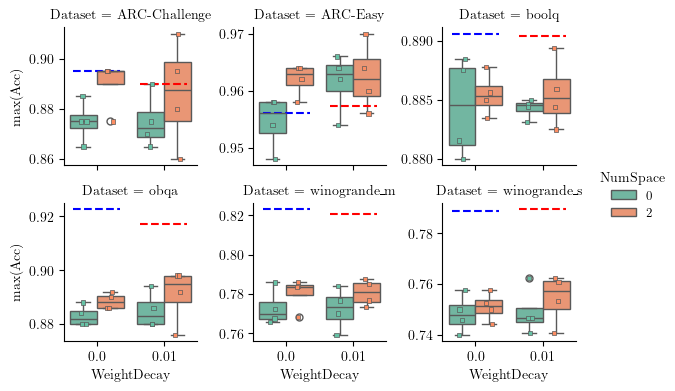

In [ ]:

g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )

g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_385792/3754934380.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

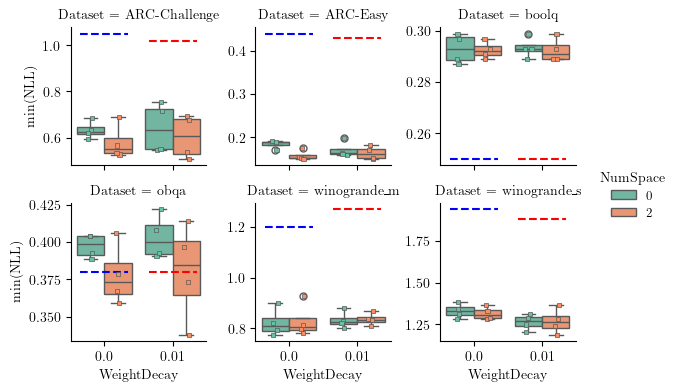

In [ ]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### with lora for lmhead and 32bit lora and new dataset

In [10]:
api = wandb.Api()
results = []
for s in ["vj9z5em9",]: # with lora for lmhead and 32bit lora and new dataset
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # drop runs with k>0 because of error in those runs
        if run.config['curve_params']['k'] == 0:
            res = dict(Id=run.id,
                        CurveSpace=run.config['curve_params']['k'],
                        Seed=run.config['rng_seed'],
                        WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                        Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                        bezierLength=run.summary.get('Curve length', 0),
                        acc_max=run.summary['final_acc_max'],
                        acc_mean=run.summary['final_acc_mean'],
                        nll_min=run.summary['final_loss_min'],
                        nll_mean=run.summary['final_loss_mean'],
                )
            results.append(res)

for s in ["0lqp05qb",]: # with lora for lmhead and 32bit lora and new dataset and no bias learning
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        # print(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)


df = pd.DataFrame(results)
df

vj9z5em9:   0%|          | 0/96 [00:00<?, ?it/s, amber-sweep-67]   

0lqp05qb: 100%|██████████| 48/48 [00:00<00:00, 381.35it/s, glorious-sweep-1]


,Id,CurveSpace,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,z51vrw9d,0,16,0.00,ARC-Easy,0.000000,0.956000,0.9560,0.271484,0.271484
1,ly92c21c,0,8,0.00,ARC-Easy,0.000000,0.958000,0.9580,0.269531,0.269531
2,t1ys9evr,0,4,0.00,ARC-Easy,0.000000,0.960000,0.9600,0.308594,0.308594
3,9581cv0o,0,1,0.00,ARC-Easy,0.000000,0.952000,0.9520,0.269531,0.269531
4,lwra1vhw,0,16,0.00,ARC-Challenge,0.000000,0.885000,0.8850,0.980469,0.980469
...,...,...,...,...,...,...,...,...,...,...
91,ybzhhopf,2,1,0.01,winogrande_s,2323.270752,0.770833,0.7586,1.140625,1.375000
92,8b40jvf1,2,16,0.01,winogrande_m,2322.336426,0.782500,0.7709,0.800781,0.929688
93,0hw1ze77,2,8,0.01,winogrande_m,2322.122070,0.785833,0.7764,0.820312,0.976562
94,uo0yf7tt,2,4,0.01,winogrande_m,2322.653809,0.787500,0.7789,0.804688,0.898438


In [11]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Seed,WeightDecay,Dataset,,,,,


In [12]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [0 2]
Seed [16  8  4  1]
WeightDecay [0.   0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'WeightDecay', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1433474547.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

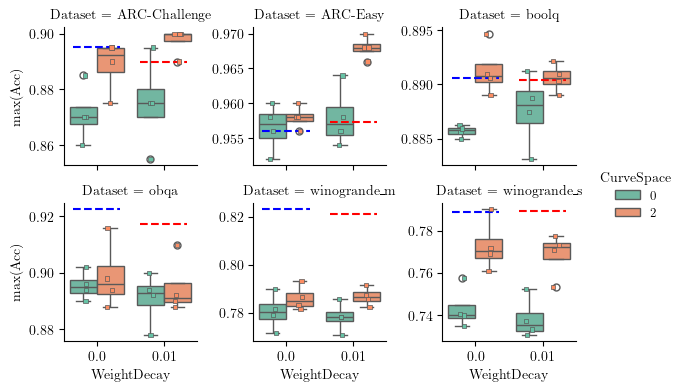

In [13]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/3804241869.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

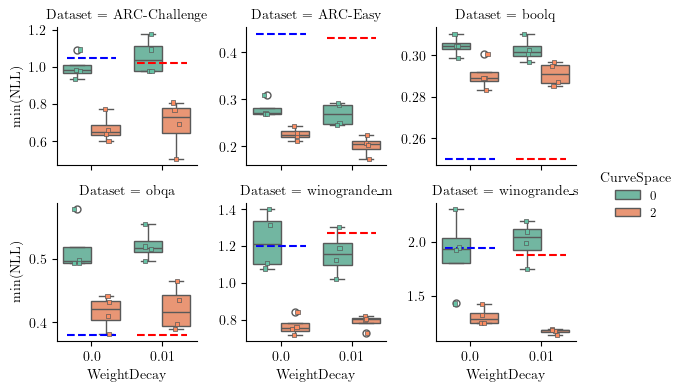

In [14]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### only curve compare with longer training 100_000 steps and different jitter and two new seeds

In [48]:
api = wandb.Api()
results = []
for s in ["tfpynhck",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

tfpynhck: 100%|██████████| 72/72 [00:00<00:00, 437.35it/s, devout-sweep-1]        


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,xpz4zlz3,2,5.0,7,0.01,ARC-Easy,11583.458984,0.296000,0.254560,1.382812,1.390625
1,u3ecxkwz,2,5.0,6,0.01,ARC-Easy,11584.446289,0.956000,0.938560,0.203125,0.277344
2,yzwme8xu,2,5.0,4,0.01,ARC-Easy,11584.413086,0.282000,0.253280,1.382812,1.390625
3,vpow0gs8,2,5.0,1,0.01,ARC-Easy,11587.439453,0.316000,0.268320,1.398438,1.445312
4,gy40kqo3,2,5.0,7,0.01,ARC-Challenge,11583.307617,0.860000,0.829600,0.843750,0.953125
...,...,...,...,...,...,...,...,...,...,...,...
67,y4geo7qb,2,1.0,7,0.01,winogrande_m,2316.600098,0.783333,0.772900,1.015625,1.156250
68,6en36155,2,1.0,1,0.01,winogrande_s,2317.422363,0.767500,0.752933,1.500000,1.804688
69,3nunf43m,2,1.0,6,0.01,winogrande_m,2316.818848,0.797500,0.786533,0.933594,1.125000
70,12tvj3l9,2,1.0,4,0.01,winogrande_m,2316.797852,0.800833,0.787866,0.933594,1.132812


In [49]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [50]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2]
Jitter [5.  0.5 1. ]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['Jitter', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4166107844.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

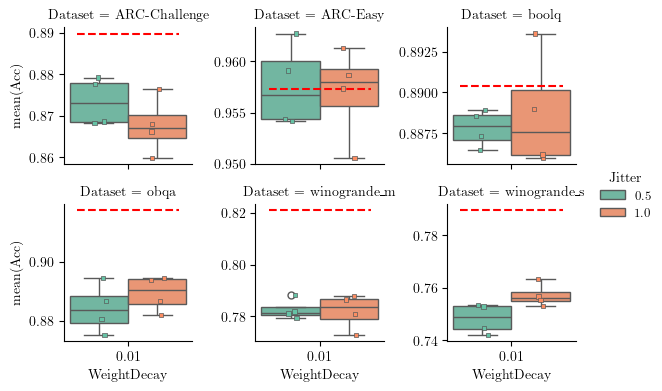

In [51]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}

df_clean = df_clean[df_clean['Jitter']<5]

g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='Jitter', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Jitter',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/1773703290.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

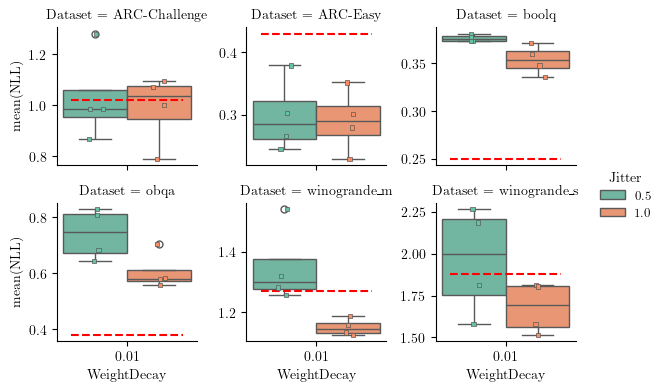

In [52]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='Jitter', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Jitter',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### Reruns from scalabl

In [53]:
api = wandb.Api()
results = []
t_run = tqdm(api.runs(f"ddold/MLE-Qwen2.5-7B-all"))
t_run.set_description(s)
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    # drop runs with k>0 because of error in those runs
    res = dict(Id=run.id,
                CurveSpace=0,
                Seed=run.config['seed'],
                Dataset=run.config['dataset'],
                WeightDecay=0,
                acc=run.summary['final_val_acc'],
                nll=run.summary['final_val_nll'],
                ece=run.summary['final_val_ece'],
        )
    results.append(res)


df = pd.DataFrame(results)
df

tfpynhck: 100%|██████████| 38/38 [00:00<00:00, 2255.51it/s, mle-boolq-seed3]


,Id,CurveSpace,Seed,Dataset,WeightDecay,acc,nll,ece
0,o1dulwhl,0,6,winogrande_s,0,0.779272,2.031250,0.205545
1,wgxbatmk,0,2,winogrande_s,0,0.775316,2.500000,0.218704
2,qvw1l26p,0,2,winogrande_s,0,0.775316,2.500000,0.218704
3,rn2t593s,0,6,winogrande_s,0,0.779272,2.031250,0.205545
4,4vjwwd1s,0,2,ARC-Challenge,0,0.898649,1.023438,0.104334
5,qo0agtmt,0,6,ARC-Challenge,0,0.898649,1.148438,0.100098
6,2ztl882y,0,6,ARC-Easy,0,0.954225,0.433594,0.042859
7,9k88c90n,0,2,ARC-Easy,0,0.955986,0.457031,0.039833
8,eu6ogm6l,0,2,winogrande_m,0,0.816456,1.203125,0.162480
9,tspr1v8i,0,6,winogrande_m,0,0.829114,1.132812,0.151753


In [54]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,acc,nll,ece
Id,CurveSpace,Seed,Dataset,WeightDecay,,,


In [55]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [0]
Seed [6 2 7 4 3 5]
Dataset ['winogrande_s' 'ARC-Challenge' 'ARC-Easy' 'winogrande_m' 'obqa' 'boolq']
WeightDecay [0]

Experiment differs in ['Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/522086511.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From 

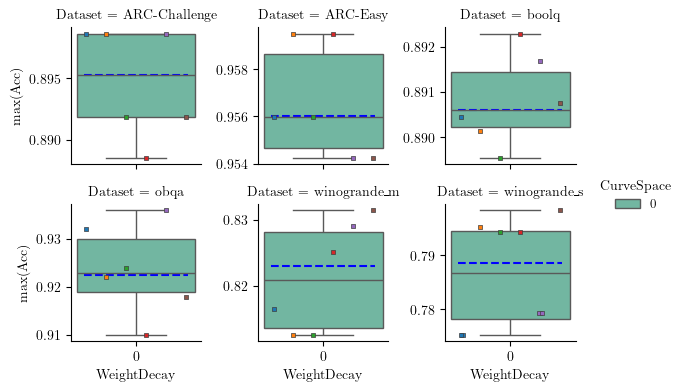

In [56]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_406738/4059220552.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

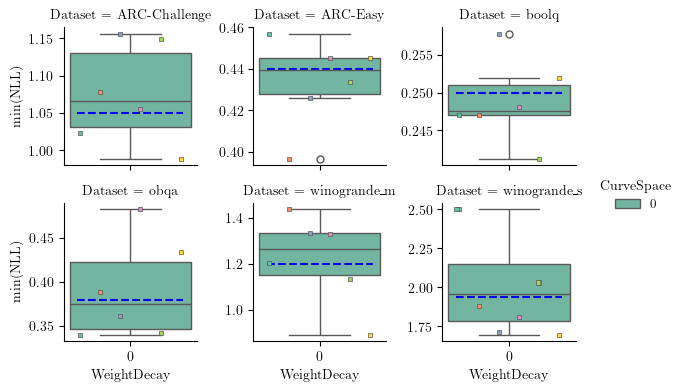

In [59]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### with new scaling behavior for LoRA (lora_alpha parameter)

In [4]:
api = wandb.Api()
results = []
for s in ["5qmpsskt",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

5qmpsskt:   0%|          | 0/40 [00:00<?, ?it/s, leafy-sweep-21]   

5qmpsskt: 100%|██████████| 40/40 [00:00<00:00, 430.25it/s, glamorous-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,ctce5vis,2,1,7,0.01,ARC-Easy,2322.504150,0.286000,0.254000,1.382812,1.382812
1,wanqj2ar,2,1,6,0.01,ARC-Easy,2322.728516,0.314000,0.262720,1.375000,1.382812
2,u9xvovko,2,1,4,0.01,ARC-Easy,2322.689453,0.300000,0.257920,1.375000,1.390625
3,948siewz,2,1,1,0.01,ARC-Easy,2323.303711,0.310000,0.260480,1.382812,1.390625
4,e568ou5g,2,1,7,0.01,ARC-Challenge,2322.484863,0.315000,0.279200,1.382812,1.484375
5,2f2n4smv,2,1,6,0.01,ARC-Challenge,2322.709717,0.310000,0.273400,1.390625,1.390625
6,iqrc2jd6,2,1,4,0.01,ARC-Challenge,2322.682129,0.310000,0.266200,1.390625,1.390625
7,c85gkqkv,2,1,1,0.01,ARC-Challenge,2323.312988,0.335000,0.266600,1.382812,1.390625
8,n3dnw2vz,2,1,7,0.01,obqa,2322.505615,0.252000,0.252000,1.382812,1.382812
9,unr0x2r3,2,1,6,0.01,obqa,2322.716064,0.314000,0.266960,1.382812,1.382812


In [5]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [6]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2 0]
Jitter [1]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


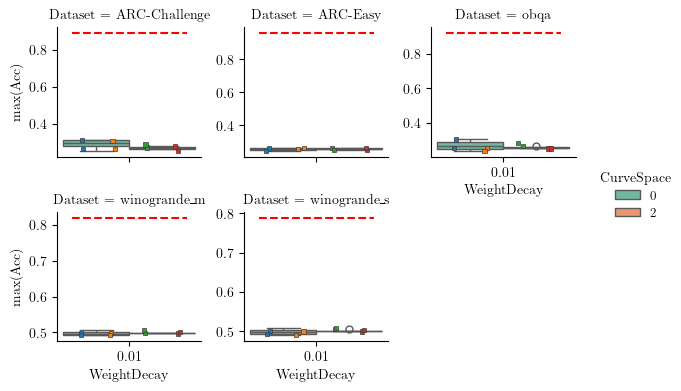

In [9]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


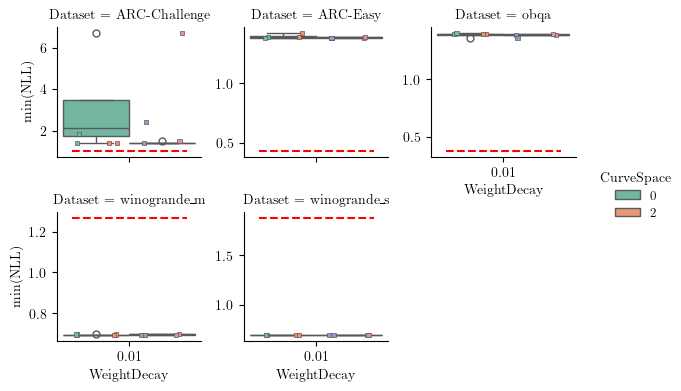

In [10]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### changed lora A matrix initialization to he_uniform 
(from he normal) with a leak_relu gain

In [11]:
api = wandb.Api()
results = []
for s in ["xe2hkb5h",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

xe2hkb5h:   0%|          | 0/48 [00:00<?, ?it/s, fragrant-sweep-39] 

xe2hkb5h: 100%|██████████| 48/48 [00:00<00:00, 227.18it/s, radiant-sweep-1]  


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,f4vwob68,2,1,7,0.01,ARC-Easy,2322.484619,0.294000,0.256960,1.382812,1.398438
1,w91ihub4,2,1,6,0.01,ARC-Easy,2322.701660,0.300000,0.257520,1.382812,1.390625
2,be2i28qa,2,1,4,0.01,ARC-Easy,2322.699219,0.296000,0.255920,1.375000,1.390625
3,2mntsbow,2,1,1,0.01,ARC-Easy,2323.312988,0.302000,0.261360,1.382812,1.398438
4,4d45ttle,2,1,7,0.01,ARC-Challenge,2322.492676,0.315000,0.257200,1.382812,1.398438
5,zx3k8ld6,2,1,6,0.01,ARC-Challenge,2322.723633,0.335000,0.284800,1.382812,1.390625
6,lfk4yxrz,2,1,4,0.01,ARC-Challenge,2322.675781,0.340000,0.291400,1.367188,1.390625
7,5e3fqg5w,2,1,1,0.01,ARC-Challenge,2323.314453,0.310000,0.257600,1.382812,1.390625
8,sr27gufy,2,1,7,0.01,obqa,2322.490234,0.276000,0.254880,1.382812,1.390625
9,7zonu1nu,2,1,6,0.01,obqa,2322.706543,0.280000,0.255840,1.382812,1.382812


In [12]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [13]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2 0]
Jitter [1]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

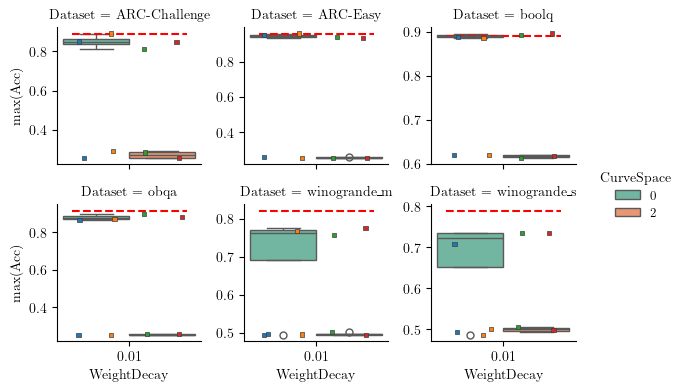

In [15]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_423182/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

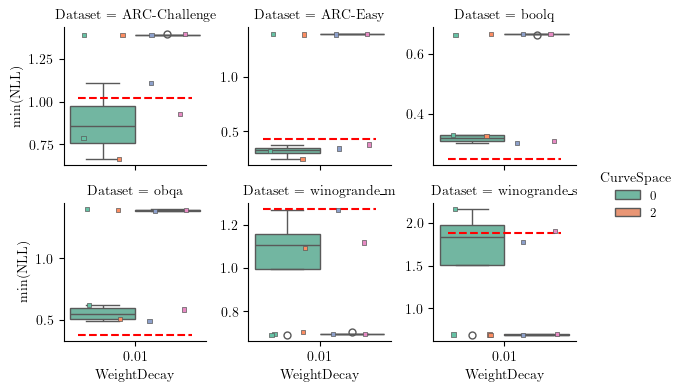

In [16]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### fixes and no noise for curve
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ no noise for curve

In [5]:
api = wandb.Api()
results = []
for s in ["0nx704d3",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

0nx704d3:   0%|          | 0/48 [00:00<?, ?it/s, vivid-sweep-37]   

0nx704d3: 100%|██████████| 48/48 [00:00<00:00, 392.13it/s, glorious-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,xqosvrr7,2,0,7,0.01,ARC-Easy,6.144023,0.956000,0.953440,0.343750,0.378906
1,ww08b05p,2,0,6,0.01,ARC-Easy,5.367301,0.968000,0.963760,0.287109,0.310547
2,mx0bd9k4,2,0,1,0.01,ARC-Easy,5.832235,0.966000,0.959280,0.222656,0.253906
3,96c2xhyj,2,0,4,0.01,ARC-Easy,5.940700,0.968000,0.964160,0.279297,0.292969
4,re7621i7,2,0,7,0.01,ARC-Challenge,5.046455,0.905000,0.895600,0.984375,1.078125
5,dcm2faci,2,0,6,0.01,ARC-Challenge,5.842677,0.900000,0.892400,0.746094,0.781250
6,ajw1nfxq,2,0,1,0.01,ARC-Challenge,6.049755,0.915000,0.907400,0.765625,0.804688
7,0dygel1f,2,0,4,0.01,ARC-Challenge,5.509381,0.895000,0.883200,0.964844,1.093750
8,j4a0fy81,2,0,7,0.01,obqa,7.142587,0.922000,0.915520,0.419922,0.435547
9,rmx5x2ji,2,0,1,0.01,obqa,7.455338,0.910000,0.902640,0.398438,0.449219


In [6]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [7]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [2 0]
Jitter [0]
Seed [7 6 1 4]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/4283118710.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

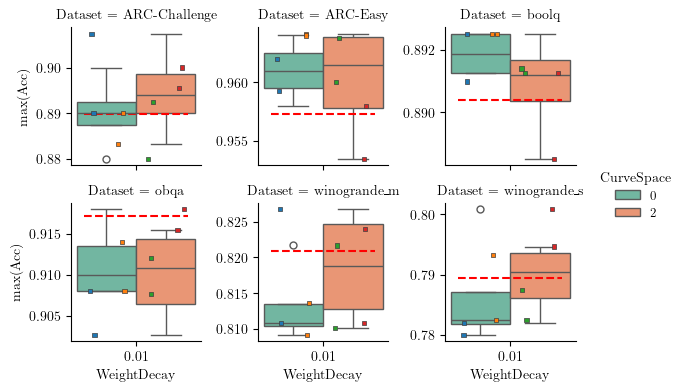

In [8]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_432165/2199332119.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

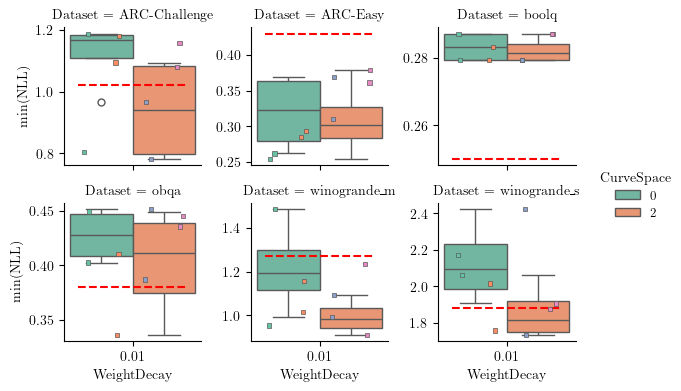

In [9]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### fixes and he_uniform init for curve
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

In [22]:
api = wandb.Api()
results = []

for s in ["0nx704d3",]: # no noise
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

for s in ["ev8m11oc",]: 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace= "{} + he_u init".format(run.config['curve_params']['k']),
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

0nx704d3:   0%|          | 0/48 [00:00<?, ?it/s, grateful-sweep-25]

ev8m11oc: 100%|██████████| 24/24 [00:00<00:00, 447.16it/s, eternal-sweep-1]


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,xqosvrr7,2,0,7,0.01,ARC-Easy,6.144023,0.956000,0.953440,0.343750,0.378906
1,96c2xhyj,2,0,4,0.01,ARC-Easy,5.940700,0.968000,0.964160,0.279297,0.292969
2,mx0bd9k4,2,0,1,0.01,ARC-Easy,5.832235,0.966000,0.959280,0.222656,0.253906
3,ww08b05p,2,0,6,0.01,ARC-Easy,5.367301,0.968000,0.963760,0.287109,0.310547
4,re7621i7,2,0,7,0.01,ARC-Challenge,5.046455,0.905000,0.895600,0.984375,1.078125
...,...,...,...,...,...,...,...,...,...,...,...
67,d54b6snc,2 + he_u init,0,1,0.01,winogrande_s,24.601696,0.783333,0.777367,2.234375,2.375000
68,0kw96szg,2 + he_u init,0,7,0.01,winogrande_m,25.156052,0.834167,0.828733,0.777344,0.917969
69,63nt1ad7,2 + he_u init,0,6,0.01,winogrande_m,25.136360,0.826667,0.821833,0.992188,1.054688
70,mp774kh1,2 + he_u init,0,4,0.01,winogrande_m,25.093098,0.831667,0.824700,0.878906,0.902344


In [23]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [24]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace ['2' '0' '2 + he_u init']
Jitter [0]
Seed [7 4 1 6]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2825472261.py:19: FutureWarning: Use "auto" to set automatic grayscale colors.

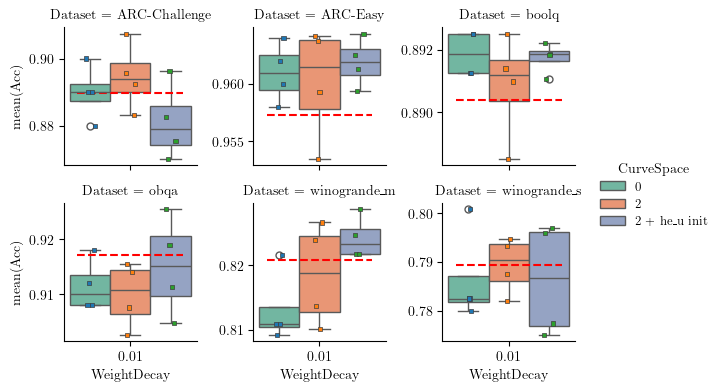

In [27]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]

# hue_order = df_clean['CurveSpace'].unique()
hue_order = ["0", "2", "2 + he_u init"]
g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_mean',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

g.legend
# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/655855814.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From 

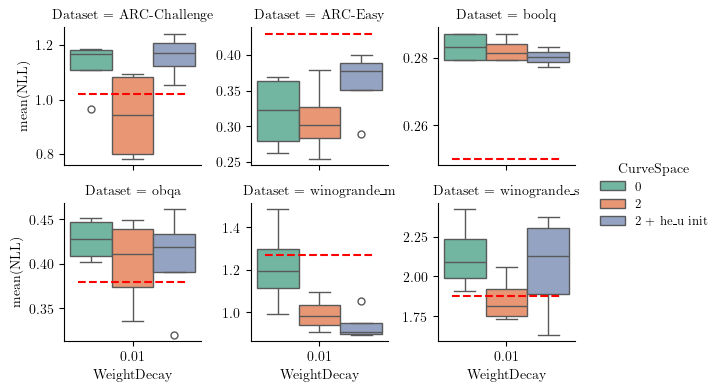

In [29]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### Wilcoxon Rank Sum Test (Independent Samples)


In [90]:
# load MLE base results
api = wandb.Api()
results = []
t_run = tqdm(api.runs(f"ddold/MLE-Qwen2.5-7B-all"))
t_run.set_description(s)
for run in t_run:
    if run.state != 'finished':
        print(f"Skipping {run.name} because it is not finished")
        continue
    t_run.set_postfix_str(run.name)
    # drop runs with k>0 because of error in those runs
    res = dict(Id=run.id,
                CurveSpace=0,
                Seed=run.config['seed'],
                Dataset=run.config['dataset'],
                WeightDecay=0,
                acc=run.summary['final_val_acc'],
                nll=run.summary['final_val_nll'],
                ece=run.summary['final_val_ece'],
        )
    results.append(res)


df_base = pd.DataFrame(results)
df_base

# drop duplicates that share the same Seed, Dataset and WeightDecay (keep first)
_before = len(df_base)
df_base = df_base.drop_duplicates(subset=['Seed', 'Dataset', 'WeightDecay'], keep='first').reset_index(drop=True)
print(f"Dropped {_before - len(df_base)} duplicates, remaining {len(df_base)} rows")
df_base

47xexal3: 100%|██████████| 45/45 [00:00<00:00, 1889.42it/s, mle-boolq-seed3]

Skipping test because it is not finished
Skipping test because it is not finished
Skipping test because it is not finished
Skipping test because it is not finished
Skipping test because it is not finished
Skipping test because it is not finished
Skipping test because it is not finished
Dropped 2 duplicates, remaining 36 rows


,Id,CurveSpace,Seed,Dataset,WeightDecay,acc,nll,ece
0,o1dulwhl,0,6,winogrande_s,0,0.779272,2.031250,0.205545
1,wgxbatmk,0,2,winogrande_s,0,0.775316,2.500000,0.218704
2,4vjwwd1s,0,2,ARC-Challenge,0,0.898649,1.023438,0.104334
3,qo0agtmt,0,6,ARC-Challenge,0,0.898649,1.148438,0.100098
4,2ztl882y,0,6,ARC-Easy,0,0.954225,0.433594,0.042859
5,9k88c90n,0,2,ARC-Easy,0,0.955986,0.457031,0.039833
6,eu6ogm6l,0,2,winogrande_m,0,0.816456,1.203125,0.162480
7,tspr1v8i,0,6,winogrande_m,0,0.829114,1.132812,0.151753
8,5tvq7zdz,0,6,obqa,0,0.936000,0.341797,0.056758
9,ndeifnz9,0,2,obqa,0,0.932000,0.339844,0.055637


In [91]:
api = wandb.Api()
results = []
for s in ["47xexal3",]: # final MLE run
# for s in ["0nx704d3",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        if run.config['curve_params']['k']>0:
            print(f"Skipping {run.name} because k>0")
            continue
        res = dict(Id=run.id,
                    CurveSpace=run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df_our = pd.DataFrame(results)
df_our

47xexal3:   0%|          | 0/72 [00:00<?, ?it/s, amber-sweep-63]  

47xexal3: 100%|██████████| 72/72 [00:00<00:00, 440.38it/s, earnest-sweep-1]   

Skipping rare-sweep-72 because k>0
Skipping whole-sweep-71 because k>0
Skipping helpful-sweep-70 because k>0
Skipping stoic-sweep-69 because k>0
Skipping good-sweep-68 because k>0
Skipping divine-sweep-67 because k>0
Skipping lemon-sweep-66 because k>0
Skipping summer-sweep-65 because k>0
Skipping snowy-sweep-64 because k>0
Skipping amber-sweep-63 because k>0
Skipping comic-sweep-62 because k>0
Skipping cerulean-sweep-61 because k>0
Skipping comic-sweep-60 because k>0
Skipping hearty-sweep-59 because k>0
Skipping honest-sweep-58 because k>0
Skipping logical-sweep-57 because k>0
Skipping serene-sweep-56 because k>0
Skipping playful-sweep-55 because k>0
Skipping different-sweep-54 because k>0
Skipping absurd-sweep-53 because k>0
Skipping crimson-sweep-52 because k>0
Skipping elated-sweep-51 because k>0
Skipping deft-sweep-50 because k>0
Skipping quiet-sweep-49 because k>0
Skipping autumn-sweep-48 because k>0
Skipping vague-sweep-47 because k>0
Skipping expert-sweep-46 because k>0
Skippin

,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,fqq9kub7,0,0,8,0,ARC-Easy,0,0.956000,0.956000,0.341797,0.341797
1,sg5qve6l,0,0,4,0,ARC-Easy,0,0.964000,0.964000,0.333984,0.333984
2,om8lcv5y,0,0,2,0,ARC-Easy,0,0.970000,0.970000,0.265625,0.265625
3,wgtt3t2r,0,0,1,0,ARC-Easy,0,0.960000,0.960000,0.316406,0.316406
4,lsipknn8,0,0,8,0,ARC-Challenge,0,0.890000,0.890000,1.148438,1.148438
5,lah4e9gh,0,0,4,0,ARC-Challenge,0,0.890000,0.890000,0.855469,0.855469
6,vyvzober,0,0,1,0,ARC-Challenge,0,0.875000,0.875000,1.179688,1.179688
7,xz9m5ysy,0,0,2,0,ARC-Challenge,0,0.875000,0.875000,1.359375,1.359375
8,wo6fc9x3,0,0,8,0,obqa,0,0.898000,0.898000,0.535156,0.535156
9,7w9ry1xx,0,0,4,0,obqa,0,0.914000,0.914000,0.361328,0.361328


#### Wilcoxon Rank Sum Test (Independent Samples)

Compare baseline (df_base) vs our method (df_our) per dataset using accuracy scores.

In [92]:
from scipy.stats import ranksums

# Prepare data for comparison
# df_base has 'acc' column, df_our has 'acc_mean' column
datasets = sorted(set(df_base['Dataset'].unique()) & set(df_our['Dataset'].unique()))

print("Wilcoxon Rank Sum Test (Mann-Whitney U test)")
print("=" * 70)
print(f"Comparing baseline vs our method per dataset")
print(f"H0: The two distributions are identical")
print(f"H1: The two distributions are different")
print("=" * 70)

results_wilcoxon = []

for dataset in datasets:
    # Get accuracy values for baseline (single model)
    base_acc = df_base[df_base['Dataset'] == dataset]['acc'].values
    
    # Get accuracy values for our method (mean of curve samples)
    our_acc = df_our[df_our['Dataset'] == dataset]['acc_mean'].values
    
    # Perform Wilcoxon rank sum test (independent samples)
    statistic, p_value = ranksums(base_acc, our_acc)
    
    # Calculate mean and std for both methods
    base_mean = base_acc.mean()
    base_std = base_acc.std()
    our_mean = our_acc.mean()
    our_std = our_acc.std()
    
    results_wilcoxon.append({
        'Dataset': dataset,
        'Base Mean': base_mean,
        'Base Std': base_std,
        'Our Mean': our_mean,
        'Our Std': our_std,
        'Statistic': statistic,
        'p-value': p_value,
        'Significant (α=0.05)': p_value < 0.05,
        'n_base': len(base_acc),
        'n_our': len(our_acc)
    })
    
    print(f"\n{dataset}:")
    print(f"  Baseline:   {base_mean:.4f} ± {base_std:.4f} (n={len(base_acc)})")
    print(f"  Our method: {our_mean:.4f} ± {our_std:.4f} (n={len(our_acc)})")
    print(f"  Statistic:  {statistic:.4f}")
    print(f"  p-value:    {p_value:.4f} {'***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'}")

df_wilcoxon = pd.DataFrame(results_wilcoxon)
print("\n" + "=" * 70)
print(f"Summary: {df_wilcoxon['Significant (α=0.05)'].sum()}/{len(df_wilcoxon)} datasets show significant differences")
df_wilcoxon

Wilcoxon Rank Sum Test (Mann-Whitney U test)
Comparing baseline vs our method per dataset
H0: The two distributions are identical
H1: The two distributions are different

ARC-Challenge:
  Baseline:   0.8947 ± 0.0041 (n=6)
  Our method: 0.8825 ± 0.0075 (n=4)
  Statistic:  2.1320
  p-value:    0.0330 *

ARC-Easy:
  Baseline:   0.9566 ± 0.0022 (n=6)
  Our method: 0.9625 ± 0.0052 (n=4)
  Statistic:  -2.1320
  p-value:    0.0330 *

boolq:
  Baseline:   0.8908 ± 0.0009 (n=6)
  Our method: 0.8907 ± 0.0011 (n=4)
  Statistic:  0.2132
  p-value:    0.8312 ns

obqa:
  Baseline:   0.9237 ± 0.0086 (n=6)
  Our method: 0.9090 ± 0.0064 (n=4)
  Statistic:  1.9188
  p-value:    0.0550 ns

winogrande_m:
  Baseline:   0.8212 ± 0.0077 (n=6)
  Our method: 0.8192 ± 0.0075 (n=4)
  Statistic:  0.4264
  p-value:    0.6698 ns

winogrande_s:
  Baseline:   0.7894 ± 0.0088 (n=6)
  Our method: 0.7923 ± 0.0017 (n=4)
  Statistic:  0.4264
  p-value:    0.6698 ns

Summary: 2/6 datasets show significant differences


,Dataset,Base Mean,Base Std,Our Mean,Our Std,Statistic,p-value,Significant (α=0.05),n_base,n_our
0,ARC-Challenge,0.894707,0.004099,0.882500,0.007500,2.132007,0.033006,True,6,4
1,ARC-Easy,0.956573,0.002196,0.962500,0.005172,-2.132007,0.033006,True,6,4
2,boolq,0.890810,0.000925,0.890703,0.001068,0.213201,0.831170,False,6,4
3,obqa,0.923667,0.008596,0.909000,0.006403,1.918806,0.055009,False,6,4
4,winogrande_m,0.821203,0.007725,0.819167,0.007477,0.426401,0.669815,False,6,4
5,winogrande_s,0.789425,0.008755,0.792292,0.001705,0.426401,0.669815,False,6,4


### longer training fixes and he_uniform init for curve
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

In [30]:
api = wandb.Api()
results = []

for s in ["ev8m11oc",]: # short training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace= "{} + 5000steps".format(run.config['curve_params']['k']),
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

for s in ["b6404m0m",]: # longer curve training 100_000 steps and different jitter and two new seeds
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace= run.config['curve_params']['k'],
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

b6404m0m:   0%|          | 0/72 [00:00<?, ?it/s, smooth-sweep-33]  

b6404m0m: 100%|██████████| 72/72 [00:00<00:00, 439.92it/s, leafy-sweep-2]    

Skipping summer-sweep-72 because it is not finished
Skipping legendary-sweep-71 because it is not finished


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean
0,gao555jn,2 + 5000steps,0,7,0.01,ARC-Easy,24.752125,0.968000,0.964400,0.332031,0.400391
1,kb15144e,2 + 5000steps,0,6,0.01,ARC-Easy,24.604591,0.964000,0.961280,0.339844,0.371094
2,l0cwt44i,2 + 5000steps,0,4,0.01,ARC-Easy,24.714027,0.966000,0.959360,0.349609,0.384766
3,es0er688,2 + 5000steps,0,1,0.01,ARC-Easy,24.707684,0.966000,0.962560,0.251953,0.289062
4,z4rhdgc3,2 + 5000steps,0,7,0.01,obqa,25.048340,0.918000,0.911360,0.380859,0.414062
...,...,...,...,...,...,...,...,...,...,...,...
89,su5990ug,0,0,1,0.01,winogrande_s,0.000000,0.777500,0.777500,3.968750,3.968750
90,lmh3t1vr,0,0,7,0.01,winogrande_m,0.000000,0.826667,0.826667,2.203125,2.203125
91,jpx832y4,0,0,6,0.01,winogrande_m,0.000000,0.809167,0.809167,2.078125,2.078125
92,fhyjaheg,0,0,1,0.01,winogrande_m,0.000000,0.819167,0.819167,1.703125,1.703125


In [31]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,


In [32]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace ['2 + 5000steps' 5 2 0]
Jitter [0]
Seed [7 6 4 1]
WeightDecay [0.01]
Dataset ['ARC-Easy' 'obqa' 'ARC-Challenge' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3551883085.py:18: FutureWarning: Use "auto" to set automatic grayscale colors.

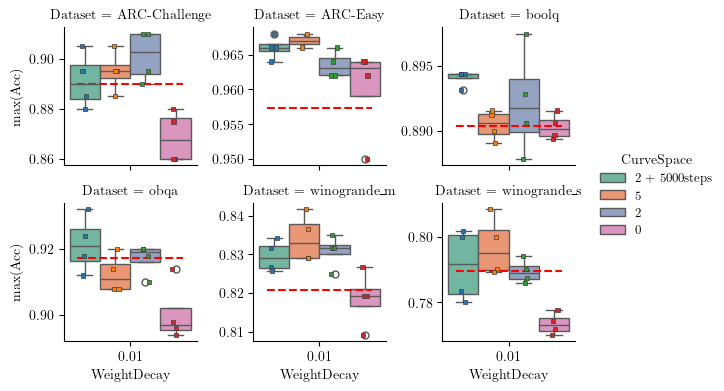

In [33]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='tab10',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_456756/3856378146.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

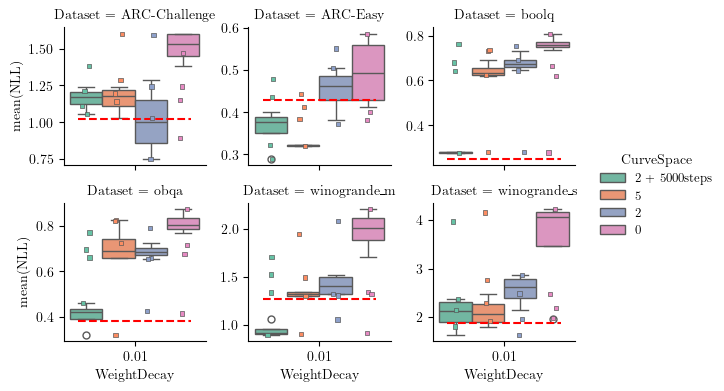

In [21]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_mean', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_mean',
        hue='Seed',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('mean(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### final MLE and MAP run
he_uniform, lora_alpha, [1,0] lora shape + fixed fan_in lora init/ he init for A lora param curve

In [56]:
api = wandb.Api()
results = []

for s in ["47xexal3",]: # MLE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
                    ece_mean=run.summary['final_ece_mean'],
                    ece_min=run.summary['final_ece_min'],
            )
        results.append(res)

for s in ["6w5rrxyg",]: # MAP training
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
                    ece_mean=run.summary['final_ece_mean'],
                    ece_min=run.summary['final_ece_min'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

47xexal3:   0%|          | 0/72 [00:00<?, ?it/s, deft-sweep-50]     

6w5rrxyg: 100%|██████████| 72/72 [00:00<00:00, 409.72it/s, serene-sweep-1]    


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean,ece_mean,ece_min
0,u8fznren,5,0,8,0.00,ARC-Easy,36.242317,0.968000,0.959200,0.281250,0.333984,0.039625,0.034137
1,0e86es3p,5,0,4,0.00,ARC-Easy,36.388222,0.962000,0.958080,0.271484,0.306641,0.039038,0.033875
2,cne60l0d,5,0,2,0.00,ARC-Easy,36.225174,0.966000,0.962080,0.275391,0.310547,0.037919,0.034375
3,38a7eclb,5,0,1,0.00,ARC-Easy,36.170921,0.964000,0.961120,0.332031,0.376953,0.037687,0.034937
4,m6ktmyb0,5,0,8,0.00,ARC-Challenge,36.590508,0.885000,0.876600,0.789062,0.886719,0.119162,0.112227
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,e1wyl9kn,0,0,2,0.01,winogrande_s,0.000000,0.778333,0.778333,2.609375,2.609375,0.219216,0.219216
140,s31mgf22,0,0,8,0.01,winogrande_m,0.000000,0.825000,0.825000,1.164062,1.164062,0.159974,0.159974
141,eyn3xg07,0,0,4,0.01,winogrande_m,0.000000,0.815833,0.815833,0.953125,0.953125,0.166989,0.166989
142,6l3sf16m,0,0,2,0.01,winogrande_m,0.000000,0.822500,0.822500,1.617188,1.617188,0.168984,0.168984


In [57]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean,ece_mean,ece_min
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,,,


In [58]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace ['5' '2' '0']
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.   0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'boolq' 'winogrande_s' 'winogrande_m']

Experiment differs in ['CurveSpace', 'WeightDecay', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

#### acc

/tmp/ipykernel_486994/3745371378.py:21: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3745371378.py:21: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3745371378.py:21: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3745371378.py:21: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3745371378.py:21: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3745371378.py:21: FutureWarning: Use "auto" to set automatic grayscale colors.

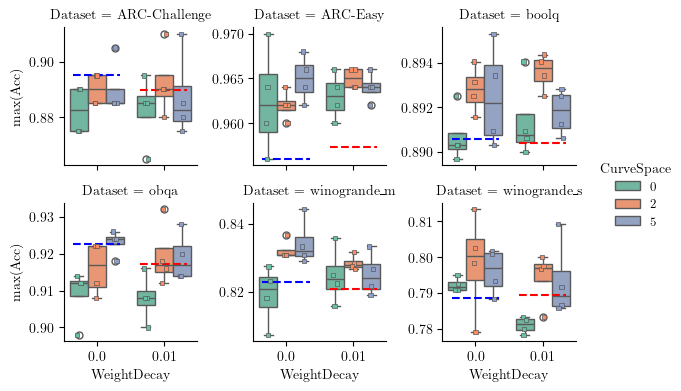

In [59]:
# Reference accuracy values from table 2
ref_acc = {
    'boolq': {'MLE': 89.06, 'MAP': 89.04},
    'ARC-Easy': {'MLE': 95.60, 'MAP': 95.73},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98},
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'winogrande_s': {'MLE': 78.86, 'MAP': 78.94},
    'winogrande_m': {'MLE': 82.30, 'MAP': 82.09}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]
hue_order = df_clean['CurveSpace'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_486994/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/1644044377.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

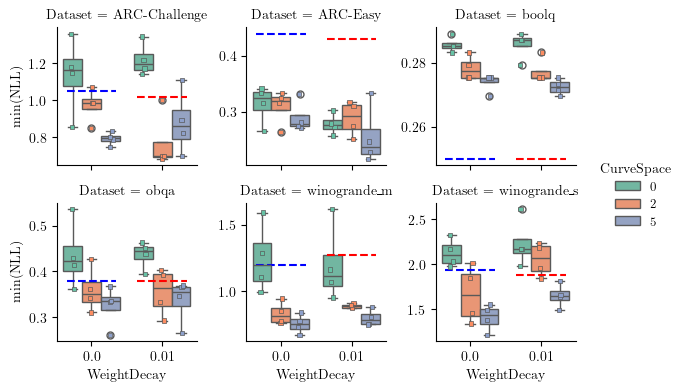

In [60]:
ref_nll = {
    'boolq': {'MLE': 0.25, 'MAP': 0.25},
    'ARC-Easy': {'MLE': 0.44, 'MAP': 0.43},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.02},
    'obqa': {'MLE': 0.38, 'MAP': 0.38},
    'winogrande_s': {'MLE': 1.94, 'MAP': 1.88},
    'winogrande_m': {'MLE': 1.20, 'MAP': 1.27}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_486994/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/3451533940.py:15: FutureWarning: Use "auto" to set automatic grayscale colors.

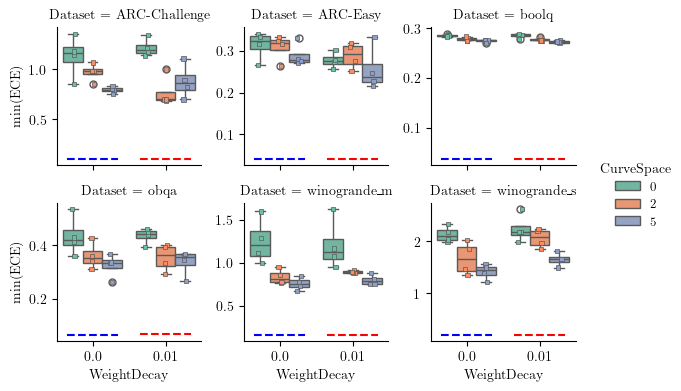

In [74]:
ref_ece = {
    'boolq': {'MLE': 3.79, 'MAP': 3.81},
    'ARC-Easy': {'MLE': 4.17, 'MAP': 4.08},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54},
    'obqa': {'MLE': 6.40, 'MAP': 6.61},
    'winogrande_s': {'MLE': 20.14, 'MAP': 19.99},
    'winogrande_m': {'MLE': 16.10, 'MAP': 16.42},
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(ECE)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_ece[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_ece[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### OOD runs

In [93]:
api = wandb.Api()
results = []

for s in ["ge0b0b5z",]: # MLE training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
                    ece_mean=run.summary['final_ece_mean'],
                    ece_min=run.summary['final_ece_min'],
            )
        results.append(res)

for s in ["ro920obt",]: # MAP training
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        res = dict(Id=run.id,
                    CurveSpace=f"{run.config['curve_params']['k']}",
                    Jitter=run.config['curve_params']['jitter_multiplier'],
                    Seed=run.config['rng_seed'],
                    WeightDecay=run.config['curve_params']['optimizer_conf']['kwargs']['weight_decay'],
                    Dataset="_".join(run.config['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
                    bezierLength=run.summary.get('Curve length', 0),
                    acc_max=run.summary['final_acc_max'],
                    acc_mean=run.summary['final_acc_mean'],
                    nll_min=run.summary['final_loss_min'],
                    nll_mean=run.summary['final_loss_mean'],
                    ece_mean=run.summary['final_ece_mean'],
                    ece_min=run.summary['final_ece_min'],
            )
        results.append(res)

df = pd.DataFrame(results)
df

ge0b0b5z:   0%|          | 0/48 [00:00<?, ?it/s, serene-sweep-19]   

ro920obt: 100%|██████████| 48/48 [00:00<00:00, 216.43it/s, good-sweep-1]          


,Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,bezierLength,acc_max,acc_mean,nll_min,nll_mean,ece_mean,ece_min
0,269mlk5g,5,0,8,0.00,ARC-Easy,0,0.956,0.94968,0.206055,0.223633,0.035600,0.029887
1,iguamb8f,5,0,4,0.00,ARC-Easy,0,0.954,0.94888,0.171875,0.200195,0.034092,0.026570
2,afxv707z,5,0,2,0.00,ARC-Easy,0,0.956,0.94776,0.199219,0.243164,0.039751,0.031516
3,ulnw7td1,5,0,1,0.00,ARC-Easy,0,0.958,0.95000,0.197266,0.208984,0.032545,0.025648
4,ulzy8kg8,5,0,8,0.00,ARC-Challenge,0,0.930,0.91880,0.357422,0.394531,0.065155,0.053652
...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,4p8cfzf0,0,0,1,0.01,MMLU_chem,0,0.500,0.50000,1.617188,1.617188,0.280508,0.280508
92,efy2o6ih,0,0,8,0.01,MMLU_phy,0,0.520,0.52000,1.289062,1.289062,0.223398,0.223398
93,lqwpl83h,0,0,4,0.01,MMLU_phy,0,0.440,0.44000,1.289062,1.289062,0.251602,0.251602
94,jtcvlzdf,0,0,2,0.01,MMLU_phy,0,0.500,0.50000,1.367188,1.367188,0.182344,0.182344


In [94]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

,,,,,,bezierLength,acc_max,acc_mean,nll_min,nll_mean,ece_mean,ece_min
Id,CurveSpace,Jitter,Seed,WeightDecay,Dataset,,,,,,,


In [95]:
df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace ['5' '2' '0']
Jitter [0]
Seed [8 4 2 1]
WeightDecay [0.   0.01]
Dataset ['ARC-Easy' 'ARC-Challenge' 'MMLU_chem' 'MMLU_phy']

Experiment differs in ['CurveSpace', 'WeightDecay', 'Dataset'] configs


array(['ARC-Challenge', 'ARC-Easy', 'MMLU_chem', 'MMLU_phy'], dtype=object)

#### acc

/tmp/ipykernel_486994/1166868836.py:20: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/1166868836.py:20: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/1166868836.py:20: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/1166868836.py:20: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


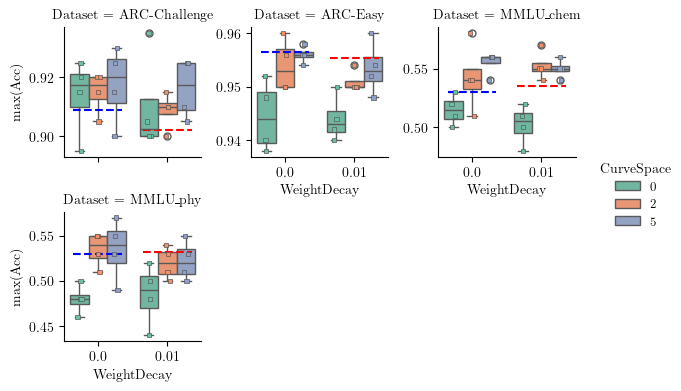

In [97]:
# Reference accuracy values from table 2
ref_acc_ood = {
    'obqa': {'MLE': 92.25, 'MAP': 91.72},
    'ARC-Challenge': {'MLE': 90.88, 'MAP': 90.20},
    'ARC-Easy': {'MLE': 95.64, 'MAP': 95.53},
    'MMLU_chem': {'MLE': 53.00, 'MAP': 53.50},
    'MMLU_phy': {'MLE': 53.00, 'MAP': 53.25}
}
# df_clean = df_clean[df_clean['CurveSpace']==0]
hue_order = df_clean['CurveSpace'].unique()
hue_order.sort()
# hue_order = hue_order[::-1]


g = sns.catplot(data=df_clean, x='WeightDecay', y='acc_max', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='acc_max',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('max(Acc)')


# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_acc_ood:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_acc_ood[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_acc_ood[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()


/tmp/ipykernel_486994/2390476435.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2390476435.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2390476435.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/2390476435.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


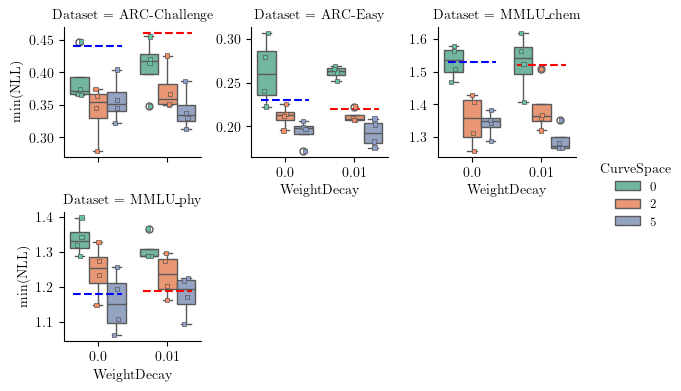

In [84]:
ref_nll_ood = {
    'obqa': {'MLE': 0.38, 'MAP': 0.39},
    'ARC-Challenge': {'MLE': 0.44, 'MAP': 0.46},
    'ARC-Easy': {'MLE': 0.23, 'MAP': 0.22},
    'MMLU_chem': {'MLE': 1.53, 'MAP': 1.52},
    'MMLU_phy': {'MLE': 1.18, 'MAP': 1.19}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(NLL)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_nll_ood:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y=ref_nll_ood[dataset]['MLE'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y=ref_nll_ood[dataset]['MAP'],
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

/tmp/ipykernel_486994/147211290.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/147211290.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/147211290.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_486994/147211290.py:14: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


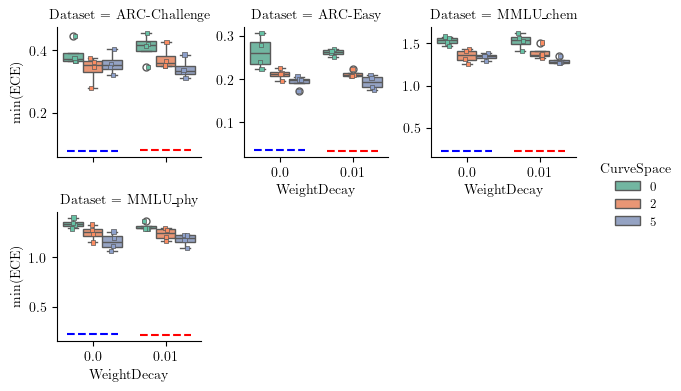

In [85]:
ref_ece_ood = {
    'obqa': {'MLE': 6.40, 'MAP': 6.61},
    'ARC-Challenge': {'MLE': 7.72, 'MAP': 7.89},
    'ARC-Easy': {'MLE': 3.48, 'MAP': 3.31},
    'MMLU_chem': {'MLE': 23.29, 'MAP': 22.90},
    'MMLU_phy': {'MLE': 23.22, 'MAP': 21.52}
}

g = sns.catplot(data=df_clean, x='WeightDecay', y='nll_min', hue='CurveSpace', kind='box', col='Dataset', sharey=False, col_wrap=3, palette='Set2', height=figsize[1], col_order=col_order, hue_order=hue_order)
for ax in g.axes.flat:
    ds = ax.get_title().split('=')[1].strip()
    # 3. Draw the stripplot onto the current axes (ax)
    # Use the axes-level function `sns.stripplot` here.
    sns.stripplot(
        data=df_clean[df_clean['Dataset'] == ds],
        x='WeightDecay',
        y='nll_min',
        hue='CurveSpace',
        ax=ax,  # <-- Tell the stripplot which axis to draw on
        palette='Set2',
        dodge=True, # <-- Aligns points with the dodged boxes
        edgecolor='gray',
        linewidth=0.5,
        size=3,
        marker="s",
        hue_order=hue_order,
        legend=False  # <-- Avoid drawing a second legend
    )
g.set_ylabels('min(ECE)')

# Extract unique weight decay levels from data (sorted)
weight_levels = sorted(df_clean['WeightDecay'].unique())

# Draw horizontal reference lines
for ax in g.axes.flatten():
    # Each subplot’s dataset name from its title
    dataset = ax.get_title().split('=')[1].strip()
    if dataset not in ref_ece_ood:
        continue

    # Get current axis limits for scaling line width
    for i, wd in enumerate(weight_levels):
        tick = i  # categorical position
        if wd == 0:
            ax.hlines(
                y= ref_ece_ood[dataset]['MLE'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='blue',
                linestyles='--',
                lw=1.5,
                label='MLE (WD=0)' if i == 0 else None
            )
        elif wd == 0.01:
            ax.hlines(
                y= ref_ece_ood[dataset]['MAP'] / 100,
                xmin=tick - 0.35,
                xmax=tick + 0.35,
                colors='red',
                linestyles='--',
                lw=1.5,
                label='MAP (WD=0.01)' if i == 0 else None
            )

# Adjust legend placement if needed
g.tight_layout()

### te